# Step 3a: Claim-Level EDA

Descriptive EDA on the cleaned, joined **claim-level** table (one row per claim) —
claim type, amounts, duration, diagnosis/procedure intensity, physician
involvement, beneficiary characteristics, patient-claim patterns, temporal
patterns, duplicate/suspicious patterns, missingness, cross-variable
relationships, and claim-level fraud-rate comparisons. All EDA code is
self-contained in this notebook (no new `src/` module) — only the existing
loading/cleaning pipeline and `src/eda.py`'s already-validated statistical
functions are reused.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
sns.set_style('whitegrid')

from src.data_loader import build_claim_level_dataset
from src.cleaning import clean_claim_level_dataset

df = clean_claim_level_dataset(build_claim_level_dataset())
df.shape

(558211, 61)

## 1. Claim Type

In [2]:
df['ClaimType'].value_counts(normalize=True).round(3)

ClaimType
Outpatient    0.927
Inpatient     0.073
Name: proportion, dtype: float64

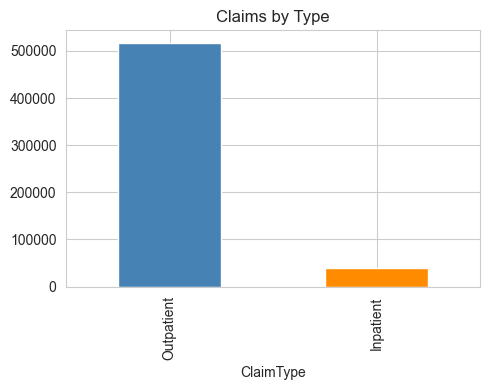

In [3]:
df['ClaimType'].value_counts().plot(kind='bar', color=['steelblue', 'darkorange'], figsize=(5, 4))
plt.title('Claims by Type')
plt.tight_layout()
plt.show()

*Outpatient dominates claim volume roughly 13:1 over inpatient.*

## 2. Claim Amounts

In [4]:
df[['InscClaimAmtReimbursed', 'DeductibleAmtPaid']].describe()

,InscClaimAmtReimbursed,DeductibleAmtPaid
count,558211.000000,558211.000000
mean,997.012133,80.014804
std,3821.534891,276.656578
min,0.000000,0.000000
25%,40.000000,0.000000
50%,80.000000,0.000000
75%,300.000000,0.000000
max,125000.000000,1068.000000


*Reimbursement is right-skewed with a huge range ($0-$125k); deductible is near-constant for inpatient, mostly $0 for outpatient.*

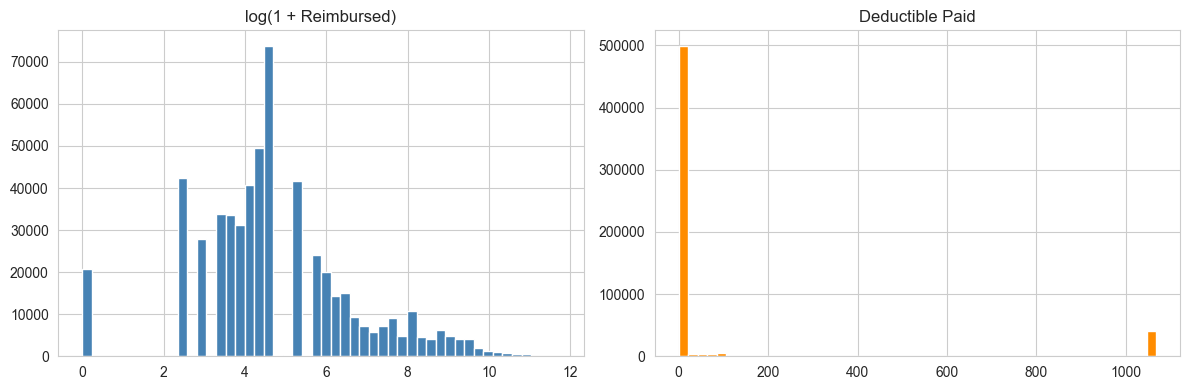

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(df['InscClaimAmtReimbursed']), bins=50, color='steelblue')
axes[0].set_title('log(1 + Reimbursed)')
axes[1].hist(df['DeductibleAmtPaid'], bins=50, color='darkorange')
axes[1].set_title('Deductible Paid')
plt.tight_layout()
plt.show()

*Deductible is bimodal (spike at 0, spike at ~1068) rather than continuous.*

In [6]:
df.nlargest(10, 'InscClaimAmtReimbursed')[['ClaimID', 'Provider', 'ClaimType', 'InscClaimAmtReimbursed']]

,ClaimID,Provider,ClaimType,InscClaimAmtReimbursed
708,CLM67392,PRV55172,Inpatient,125000
20124,CLM31106,PRV52815,Inpatient,125000
22893,CLM59310,PRV56044,Inpatient,125000
34034,CLM56796,PRV54742,Inpatient,125000
39514,CLM44467,PRV53461,Inpatient,125000
832,CLM54264,PRV54942,Inpatient,124000
5911,CLM31780,PRV52467,Inpatient,123000
4774,CLM45826,PRV57173,Inpatient,120000
32210,CLM68762,PRV53706,Inpatient,119000
21807,CLM75041,PRV52845,Inpatient,118000


*The highest-value claims are all Inpatient, as expected.*

## 3. Claim Duration

In [7]:
df['ClaimDuration'] = (df['ClaimEndDt'] - df['ClaimStartDt']).dt.days
df['LengthOfStay'] = (df['DischargeDt'] - df['AdmissionDt']).dt.days
df[['ClaimDuration', 'LengthOfStay']].describe()

,ClaimDuration,LengthOfStay
count,558211.000000,40474.000000
mean,1.727940,5.665168
std,4.904984,5.638538
min,0.000000,0.000000
25%,0.000000,2.000000
50%,0.000000,4.000000
75%,0.000000,7.000000
max,36.000000,35.000000


*`ClaimDuration` averages just 1.7 days (mostly same-day Outpatient visits); `LengthOfStay` (Inpatient-only) averages 5.7 days — these are not the same thing.*

In [8]:
same_day = (df['ClaimDuration'] == 0).sum()
print(f'Same-day claims: {same_day:,} ({same_day / len(df) * 100:.1f}%)')

Same-day claims: 453,953 (81.3%)


*Most claims are same-day — driven by the Outpatient majority.*

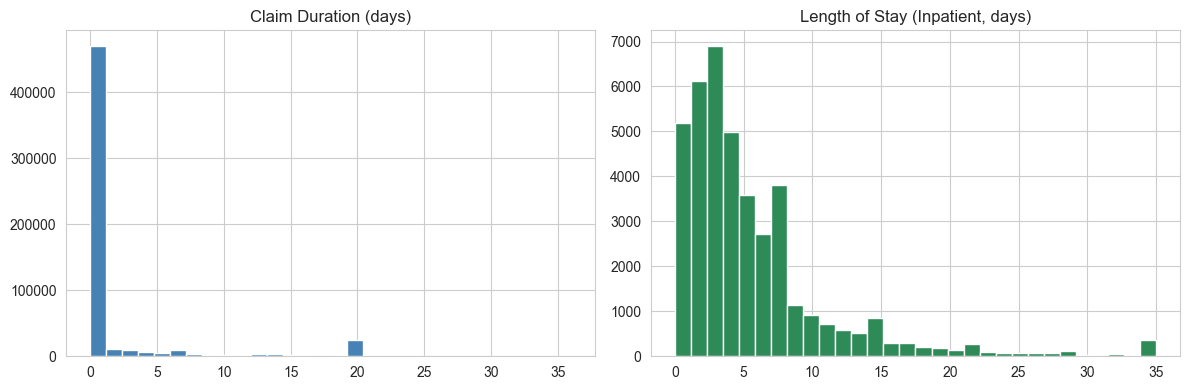

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['ClaimDuration'].dropna(), bins=30, color='steelblue')
axes[0].set_title('Claim Duration (days)')
axes[1].hist(df['LengthOfStay'].dropna(), bins=30, color='seagreen')
axes[1].set_title('Length of Stay (Inpatient, days)')
plt.tight_layout()
plt.show()

*Claim duration is dominated by same-day outpatient visits; length of stay (inpatient-only) is more spread out.*

## 4. Diagnosis Intensity

In [10]:
diag_cols = [f'ClmDiagnosisCode_{i}' for i in range(1, 11)]
df['NumDiagnosisCodes'] = df[diag_cols].notna().sum(axis=1)
df['NumDiagnosisCodes'].describe()

count    558211.000000
mean          3.010897
std           2.448213
min           0.000000
25%           1.000000
50%           2.000000
75%           4.000000
max          10.000000
Name: NumDiagnosisCodes, dtype: float64

*Median is 2 codes per claim (mean 3.0), ranging 0-10.*

In [11]:
print('Claims with zero diagnosis codes:', (df['NumDiagnosisCodes'] == 0).sum())
print('Missing ClmDiagnosisCode_1:', df['ClmDiagnosisCode_1'].isna().sum(),
      f"({df['ClmDiagnosisCode_1'].isna().mean() * 100:.2f}%)")

Claims with zero diagnosis codes: 10453
Missing ClmDiagnosisCode_1: 10453 (1.87%)


*Primary diagnosis is almost always present; fully diagnosis-less claims are rare.*

In [12]:
df['ClmDiagnosisCode_1'].value_counts().head(10)

ClmDiagnosisCode_1
4019     13886
4011     12512
2724      3606
2720      3210
2722      3028
2721      2998
2723      2995
78659     2687
42731     2619
78650     2384
Name: count, dtype: int64

*Top codes are dominated by hypertension and lipid-disorder ICD-9 codes (4019, 4011, 2724...) — chronic-condition-driven, consistent with the outpatient-heavy population.*

## 5. Procedure Intensity

In [13]:
proc_cols = [f'ClmProcedureCode_{i}' for i in range(1, 7)]
df['NumProcedureCodes'] = df[proc_cols].notna().sum(axis=1)
df['NumProcedureCodes'].describe()

count    558211.000000
mean          0.053557
std           0.280534
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           5.000000
Name: NumProcedureCodes, dtype: float64

*Median is 0 — most claims (mainly Outpatient) have no procedure code at all.*

In [14]:
has_procedure = df['NumProcedureCodes'] > 0
print(f"Claims with >=1 procedure code: {has_procedure.sum():,} ({has_procedure.mean() * 100:.1f}%)")
df.groupby('ClaimType')['NumProcedureCodes'].apply(lambda x: (x > 0).mean()).round(3)

Claims with >=1 procedure code: 23,310 (4.2%)


ClaimType
Inpatient     0.572
Outpatient    0.000
Name: NumProcedureCodes, dtype: float64

*Procedure codes are almost exclusively an Inpatient phenomenon.*

In [15]:
df['ClmProcedureCode_1'].value_counts().head(10)

ClmProcedureCode_1
9904    1152
8154    1022
66       900
3893     854
3995     809
4516     651
3722     589
8151     463
8872     411
9671     402
Name: count, dtype: int64

*Top procedure codes are common inpatient interventions (e.g. transfusions, respiratory/cardiac procedures).*

## 6. Physician Involvement

In [16]:
df['NumPhysiciansInvolved'].value_counts().sort_index()

NumPhysiciansInvolved
0      1483
1    286625
2    226048
3     44055
Name: count, dtype: int64

*Most claims involve 1-2 physicians; already derived in `src/cleaning.py`.*

In [17]:
for col in ['AttendingPhysician', 'OperatingPhysician', 'OtherPhysician']:
    print(f"{col}: {df[col].notna().mean() * 100:.1f}% present")

AttendingPhysician: 99.7% present
OperatingPhysician: 20.5% present
OtherPhysician: 35.8% present


*Attending is almost always present; Operating/Other are structurally sparse (not every claim involves surgery or a second physician).*

In [18]:
same_doc = (df['AttendingPhysician'] == df['OperatingPhysician']) & df['OperatingPhysician'].notna()
print(f"Claims where Attending == Operating physician: {same_doc.sum():,} ({same_doc.mean() * 100:.2f}%)")

Claims where Attending == Operating physician: 61,164 (10.96%)


*A modest but non-trivial share of claims have the same physician in both roles.*

## 7. Beneficiary Characteristics

In [19]:
df['AgeAtClaim'].describe()

count    558211.000000
mean         73.297705
std          13.017286
min          25.092402
25%          67.542779
50%          74.203970
75%          81.954825
max         100.993840
Name: AgeAtClaim, dtype: float64

*Centered around 65-85, consistent with Medicare eligibility.*

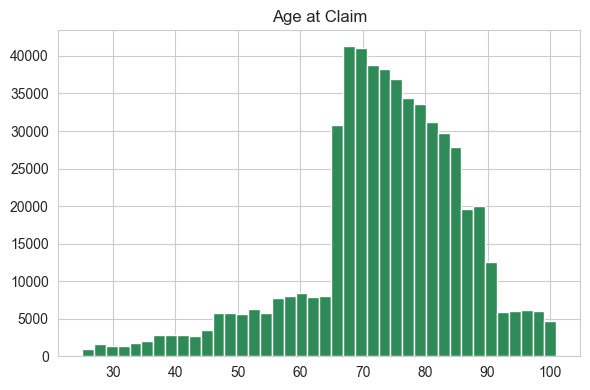

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df['AgeAtClaim'].dropna(), bins=40, color='seagreen')
ax.set_title('Age at Claim')
plt.tight_layout()
plt.show()

*Roughly bell-shaped, slight left skew toward older ages.*

In [21]:
print('Gender:'); print(df['Gender'].value_counts(normalize=True).round(3))
print('\nRace:'); print(df['Race'].value_counts(normalize=True).round(3))

Gender:
Gender
2    0.579
1    0.421
Name: proportion, dtype: float64

Race:
Race
1    0.844
2    0.100
3    0.035
5    0.021
Name: proportion, dtype: float64


*Race is heavily skewed toward one code (~85%+); Gender is fairly balanced.*

In [22]:
chronic_cols = [c for c in df.columns if c.startswith('ChronicCond_')]
df['NumChronicConditions'] = df[chronic_cols].sum(axis=1)
print('Avg chronic conditions per claim:', df['NumChronicConditions'].mean().round(2))
print('RenalDiseaseIndicator rate:', df['RenalDiseaseIndicator'].mean().round(3))

Avg chronic conditions per claim: 4.5
RenalDiseaseIndicator rate: 0.197


*Beneficiaries behind these claims average ~4.5 chronic conditions — a genuinely comorbid population.*

## 8. Patient-Claim Relationship

In [23]:
claims_per_bene = df.groupby('BeneID').size()
claims_per_bene.describe()

count    138556.000000
mean          4.028775
std           3.229291
min           1.000000
25%           2.000000
50%           3.000000
75%           5.000000
max          29.000000
dtype: float64

*Median beneficiary has very few claims; a long tail of high-utilization patients exists.*

In [24]:
claims_per_bene.sort_values(ascending=False).head(10)

BeneID
BENE118316    29
BENE42721     29
BENE59303     29
BENE44241     28
BENE80977     28
BENE36330     28
BENE40202     27
BENE143400    27
BENE63544     27
BENE63504     27
dtype: int64

*Top beneficiaries have 20-30+ claims in the year — worth watching as a utilization outlier group.*

In [25]:
multi_claim_bene = df[df['BeneID'].isin(claims_per_bene[claims_per_bene > 1].index)].sort_values(['BeneID', 'ClaimStartDt'])
gap_days = multi_claim_bene.groupby('BeneID')['ClaimStartDt'].diff().dt.days
print('Claims within 7 days of the same beneficiary\'s prior claim:', (gap_days <= 7).sum())
print('Claims within 30 days of the same beneficiary\'s prior claim:', (gap_days <= 30).sum())

Claims within 7 days of the same beneficiary's prior claim: 62855
Claims within 30 days of the same beneficiary's prior claim: 197478


*11.3% of claims fall within 7 days of the same beneficiary's prior claim, 35.4% within 30 days — a meaningful amount of temporal clustering.*

## 9. Temporal Patterns

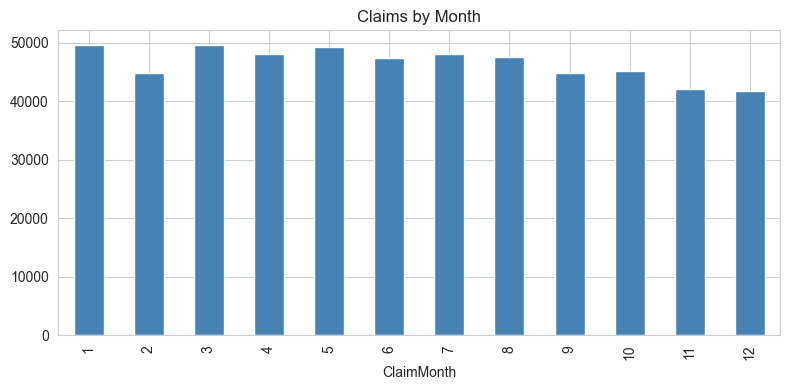

In [26]:
df['ClaimMonth'] = df['ClaimStartDt'].dt.month
df['ClaimMonth'].value_counts().sort_index().plot(kind='bar', figsize=(8, 4), color='steelblue')
plt.title('Claims by Month')
plt.tight_layout()
plt.show()

*Claim volume is fairly stable month-to-month across the ~13-month window (Nov 2008-Dec 2009).*

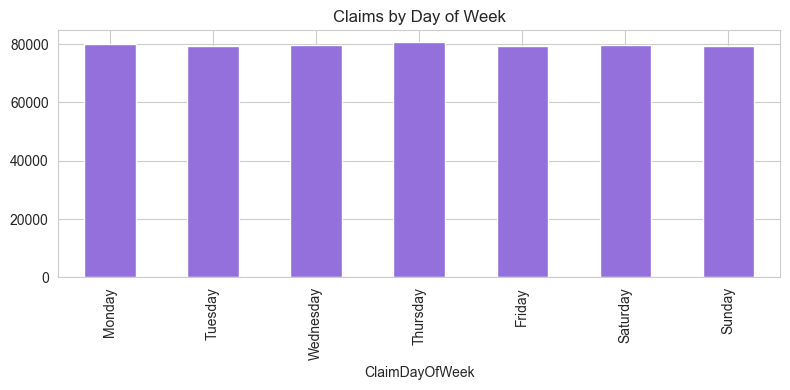

In [27]:
df['ClaimDayOfWeek'] = df['ClaimStartDt'].dt.day_name()
df['ClaimDayOfWeek'].value_counts().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
).plot(kind='bar', figsize=(8, 4), color='mediumpurple')
plt.title('Claims by Day of Week')
plt.tight_layout()
plt.show()

In [28]:
weekend_rate = df['ClaimDayOfWeek'].isin(['Saturday', 'Sunday']).mean()
print(f'Weekend claim rate: {weekend_rate * 100:.1f}%')

Weekend claim rate: 28.5%


*Weekend rate (28.5%) is essentially the 28.6% uniform-week baseline (2/7 days) — no real weekday/weekend skew.*

In [29]:
claims_per_date = df.groupby('ClaimStartDt').size()
claims_per_date.describe()

count     398.000000
mean     1402.540201
std       412.071247
min         1.000000
25%      1435.500000
50%      1540.000000
75%      1596.750000
max      1709.000000
dtype: float64

*~1,400 claims/day on average across 398 unique dates; the min (1 claim) is likely the partial first/last day at the edge of the observation window, not a red flag.*

## 10. Duplicate / Suspicious Patterns

In [30]:
dup_bene_provider_date = df.duplicated(subset=['BeneID', 'Provider', 'ClaimStartDt'], keep=False)
print(f"Claims sharing the same BeneID + Provider + ClaimStartDt: {dup_bene_provider_date.sum():,}")

Claims sharing the same BeneID + Provider + ClaimStartDt: 2,798


*A small number of same-day, same-patient, same-provider claim pairs exist — worth a closer look as a potential billing-error or split-billing signal.*

In [31]:
df['InscClaimAmtReimbursed'].value_counts().head(10)

InscClaimAmtReimbursed
100    52960
10     42463
200    41634
60     40764
30     33920
40     33617
50     31297
20     27964
80     25101
70     24415
Name: count, dtype: int64

*A handful of exact reimbursement amounts repeat heavily — likely standard billing-code rates, not necessarily suspicious on their own.*

In [32]:
diag_proc_combo = df[['ClmDiagnosisCode_1', 'ClmProcedureCode_1']].dropna()
diag_proc_combo.value_counts().head(10)

ClmDiagnosisCode_1  ClmProcedureCode_1
41401               66                    443
71536               8154                  422
43310               3812                  191
71536               8151                  186
V5789               9339                  179
41401               3722                  177
71535               8154                  158
41071               66                    156
51881               9671                  147
71596               8154                  138
Name: count, dtype: int64

*A few diagnosis-procedure pairings repeat often — plausibly routine standard-of-care combinations.*

## 11. Missingness

In [33]:
missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing.head(15)

ClmProcedureCode_6     100.000000
ClmProcedureCode_5      99.998388
ClmProcedureCode_4      99.978861
ClmProcedureCode_3      99.826410
DOD                     99.259957
ClmDiagnosisCode_10     99.102490
ClmProcedureCode_2      99.016501
ClmProcedureCode_1      95.824160
LengthOfStay            92.749337
DiagnosisGroupCode      92.749337
DischargeDt             92.749337
AdmissionDt             92.749337
ClmDiagnosisCode_9      92.509105
ClmDiagnosisCode_8      90.425843
ClmDiagnosisCode_7      88.144805
dtype: float64

*Top missingness is all structural (procedure/diagnosis code slots, Inpatient-only columns, DOD) — matches what the individual raw-table EDA notebooks already found.*

In [34]:
phys_cols = ['AttendingPhysician', 'OperatingPhysician', 'OtherPhysician']
df.groupby('ClaimType')[phys_cols].apply(lambda x: x.notna().mean()).round(3)

,AttendingPhysician,OperatingPhysician,OtherPhysician
ClaimType,,,
Inpatient,0.997,0.589,0.116
Outpatient,0.997,0.175,0.377


*Operating physician presence is far higher for Inpatient claims, consistent with surgery being an inpatient-heavy event.*

In [35]:
df.groupby('ClaimType')[['ClmDiagnosisCode_1', 'ClmProcedureCode_1']].apply(lambda x: x.notna().mean()).round(3)

,ClmDiagnosisCode_1,ClmProcedureCode_1
ClaimType,,
Inpatient,1.00,0.572
Outpatient,0.98,0.000


*Procedure coding is almost entirely an Inpatient behavior; diagnosis coding is populated for both claim types.*

## 12. Relationships Between Variables

In [36]:
print('Corr(ClaimDuration, InscClaimAmtReimbursed):', df[['ClaimDuration', 'InscClaimAmtReimbursed']].corr().iloc[0, 1].round(3))
print('Corr(NumDiagnosisCodes, InscClaimAmtReimbursed):', df[['NumDiagnosisCodes', 'InscClaimAmtReimbursed']].corr().iloc[0, 1].round(3))
print('Corr(NumProcedureCodes, InscClaimAmtReimbursed):', df[['NumProcedureCodes', 'InscClaimAmtReimbursed']].corr().iloc[0, 1].round(3))

Corr(ClaimDuration, InscClaimAmtReimbursed): 0.257
Corr(NumDiagnosisCodes, InscClaimAmtReimbursed): 0.418
Corr(NumProcedureCodes, InscClaimAmtReimbursed): 0.626


*`NumProcedureCodes` correlates most strongly with reimbursement (r=0.63); `NumDiagnosisCodes` is moderate (r=0.42); `ClaimDuration` is weakest (r=0.26).*

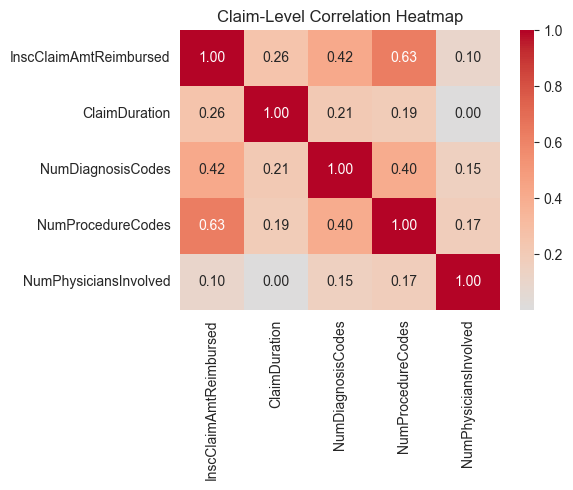

In [37]:
numeric_cols = ['InscClaimAmtReimbursed', 'ClaimDuration', 'NumDiagnosisCodes', 'NumProcedureCodes', 'NumPhysiciansInvolved']
corr = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Claim-Level Correlation Heatmap')
plt.tight_layout()
plt.show()

*Claim complexity (diagnosis/procedure counts) correlates with amount more than duration or physician count does.*

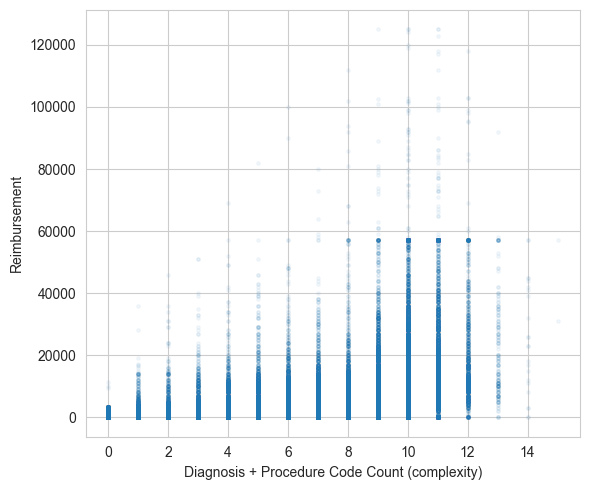

In [38]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df['NumDiagnosisCodes'] + df['NumProcedureCodes'], df['InscClaimAmtReimbursed'], alpha=0.05, s=6)
ax.set_xlabel('Diagnosis + Procedure Code Count (complexity)')
ax.set_ylabel('Reimbursement')
plt.tight_layout()
plt.show()

*Higher-complexity claims trend toward higher reimbursement, but with wide spread at every complexity level.*

## 13. Fraud-Rate Comparisons

Moved here from the original `03_eda_stats.ipynb` — these are computed directly on claim-level rows (not a provider-level aggregate), reusing `src/eda.py`'s already-validated functions (the same ones `03b_provider_level_eda.ipynb` depends on) rather than reimplementing the statistics.

In [39]:
from src.eda import plot_fraud_rate_by_category, chi_square_test, cramers_v, plot_benford_comparison, benford_test_by_fraud_group

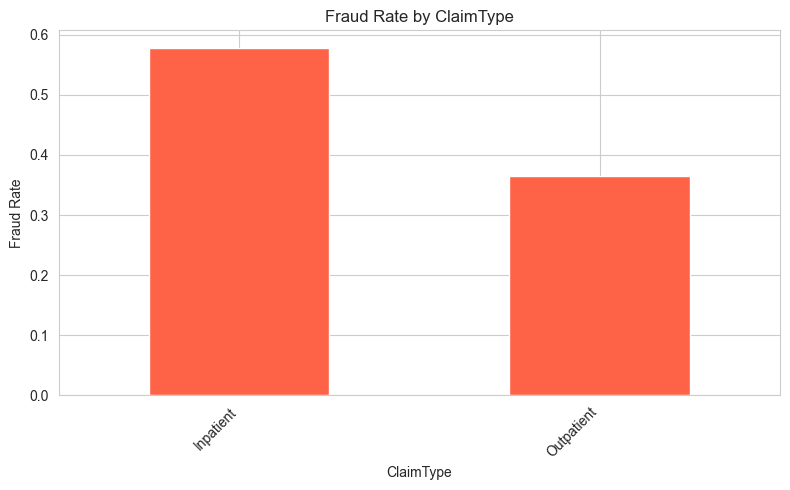

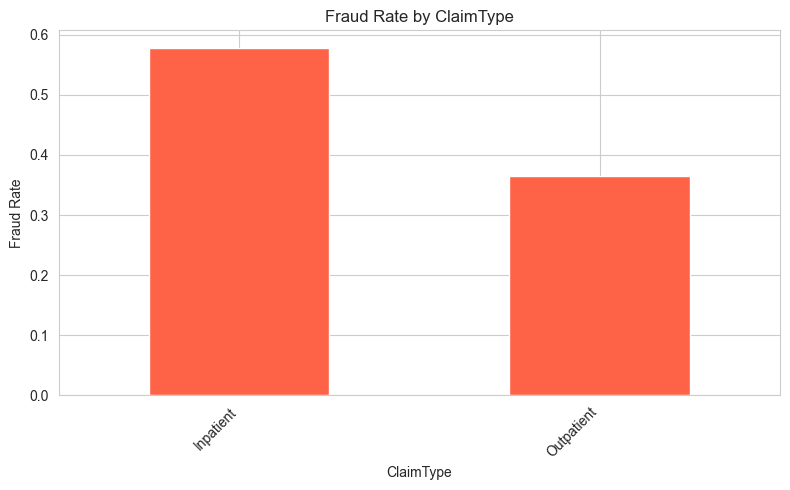

In [40]:
plot_fraud_rate_by_category(df, 'ClaimType')

*Inpatient claims have a meaningfully higher fraud rate (~0.57) than Outpatient (~0.37).*

/Users/tanyumin/Downloads/bt4012_grp14/bt4012-group14-healthcare-fraud-detection/notebooks/../src/eda.py:101: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rate = df.groupby(categorical_col)["PotentialFraud"].mean().sort_values(ascending=False).head(top_n)


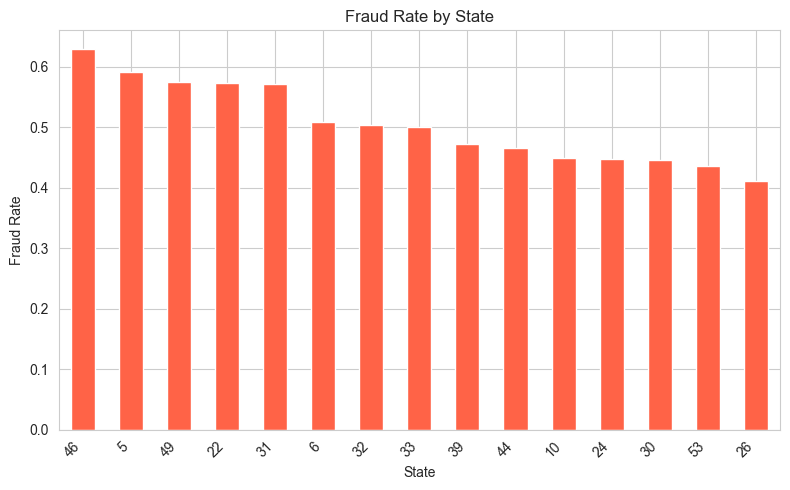

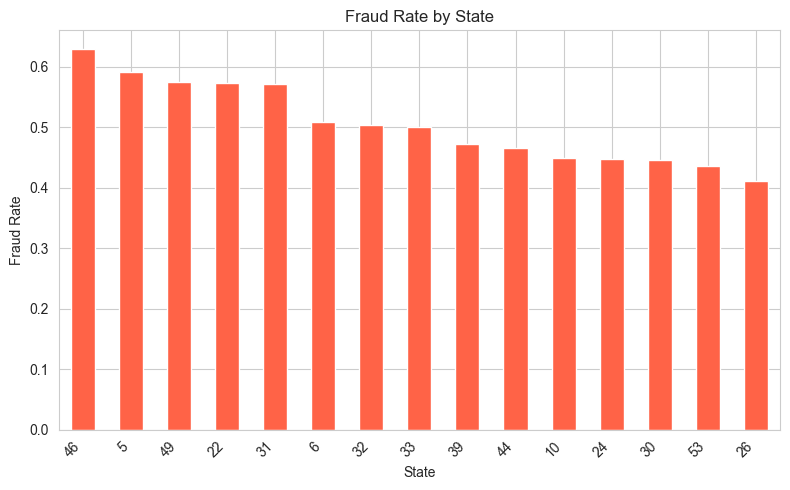

In [41]:
plot_fraud_rate_by_category(df, 'State', top_n=15)

*Real variation across states (top ~0.63, lowest shown ~0.42) — caveat: states with few providers can show noisy, extreme rates purely from small sample size.*

In [42]:
print(chi_square_test(df, 'ClaimType'))
print(f"Cramer's V: {cramers_v(df, 'ClaimType'):.4f}")

{'test': 'chi-square', 'column': 'ClaimType', 'chi2_statistic': np.float64(7177.629110563149), 'p_value': np.float64(0.0), 'degrees_of_freedom': 1, 'contingency_table': PotentialFraud       0       1
ClaimType                     
Inpatient        17072   23402
Outpatient      328343  189394}
Cramer's V: 0.1134


*Cramér's V = 0.11 — a real but small-to-moderate association between `ClaimType` and fraud, not just statistically detectable at large n.*

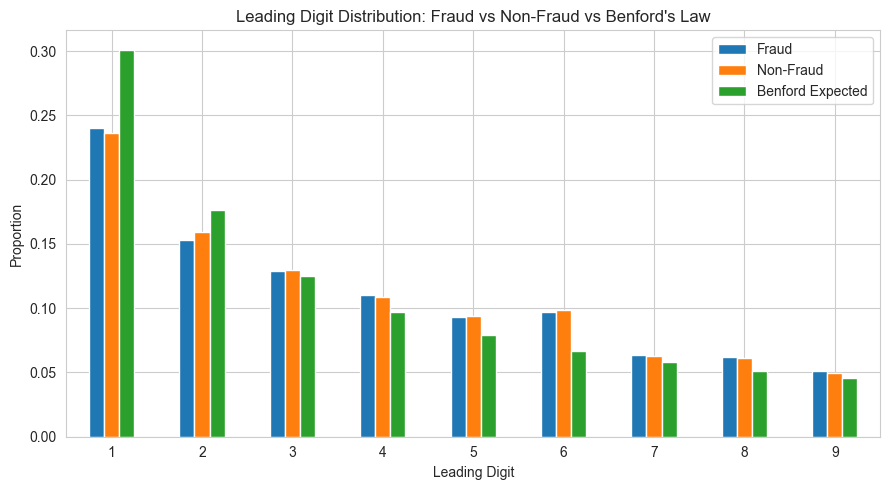

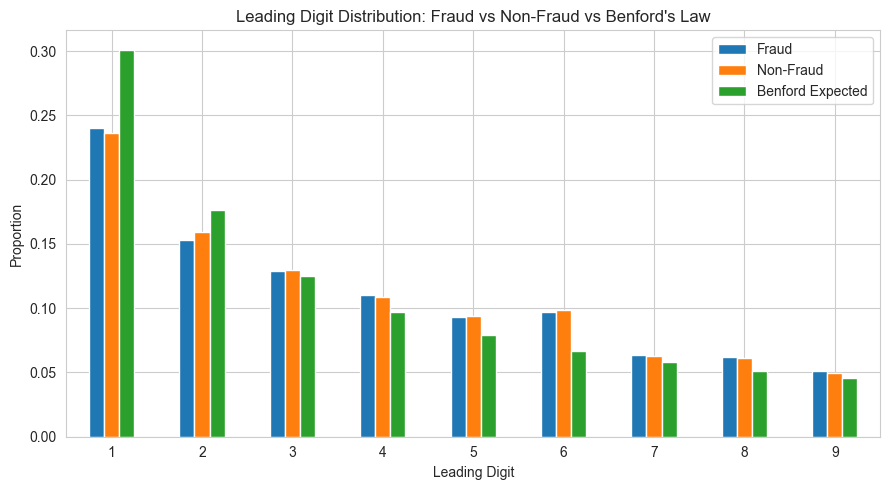

In [43]:
plot_benford_comparison(df)

In [44]:
benford_test_by_fraud_group(df)

{'fraud_group': {'test': "Benford's Law (chi-square goodness of fit)",
  'chi2_statistic': np.float64(7587.879114555467),
  'p_value': np.float64(0.0),
  'observed_proportions': {1: 0.24,
   2: 0.1533,
   3: 0.1291,
   4: 0.1105,
   5: 0.0934,
   6: 0.0972,
   7: 0.0637,
   8: 0.0617,
   9: 0.0512},
  'expected_proportions': {1: np.float64(0.301),
   2: np.float64(0.1761),
   3: np.float64(0.1249),
   4: np.float64(0.0969),
   5: np.float64(0.0792),
   6: np.float64(0.0669),
   7: np.float64(0.058),
   8: np.float64(0.0512),
   9: np.float64(0.0458)},
  'mad': np.float64(0.018646300751390732)},
 'non_fraud_group': {'test': "Benford's Law (chi-square goodness of fit)",
  'chi2_statistic': np.float64(12364.60139149938),
  'p_value': np.float64(0.0),
  'observed_proportions': {1: 0.2366,
   2: 0.1592,
   3: 0.1299,
   4: 0.1086,
   5: 0.0938,
   6: 0.0984,
   7: 0.0625,
   8: 0.0611,
   9: 0.0499},
  'expected_proportions': {1: np.float64(0.301),
   2: np.float64(0.1761),
   3: np.float64

*MAD is nearly identical between Fraud (0.0186) and Non-Fraud (0.0181) once corrected for sample-size — Benford's Law is not a strong standalone fraud signal here, likely because reimbursement amounts are fee-schedule/policy-constrained rather than organically occurring.*

## Summary

Claim-level behavior is dominated by high-volume, low-value Outpatient
visits, with a smaller, higher-value, more complex Inpatient minority
driving most of the extreme amounts, longer durations, and procedure
coding. Missingness is almost entirely structural (claim-type-driven), a
meaningful tail of high-utilization/rapid-repeat beneficiaries exists, and
no single variable (duration, diagnosis count, procedure count) dominates
reimbursement on its own — consistent with the provider-level finding in
`03b_provider_level_eda.ipynb` that volume and amount statistics, not
individual claim traits, carry the strongest fraud signal.

The claim-level fraud-rate comparisons above reinforce this: `ClaimType`
has a real but small-to-moderate association with fraud (Cramér's V =
0.11), and leading-digit deviation from Benford's Law is not a
discriminating signal once sample-size effects are corrected for (MAD
0.0186 fraud vs. 0.0181 non-fraud) — plausibly because reimbursement
amounts are fee-schedule-constrained rather than organically occurring,
a known limitation of applying Benford's Law to regulated billing data.